# Used Tractor Auction Prices: Model Training, Validation and Testing

This notebook fits predictive models to the cleaned tractor-auction sample produced by the EDA notebook.

The modelling sequence is deliberately transparent:

1. retain a currency-specific training median only as a naive validation sanity reference;
2. fit an additive linear regression;
3. fit a limited quadratic regression, which serves as the substantive transparent benchmark;
4. inspect regression residuals;
5. compare a Decision Tree, XGBoost and CatBoost;
6. select one model using the validation set only;
7. refit the selected model and quadratic benchmark on the combined training-validation sample; and
8. evaluate both once on the untouched test sample.

The target is logged and robustly standardised within currency for model fitting and fair cross-currency selection. **Reporting is then returned to actual sale-price units.** Native-currency MAE, RMSE and median absolute error are reported separately for each currency, because pooling pounds, dollars and euros into one raw-unit MAE would have no coherent unit. **MedAPE is the principal cross-currency accuracy metric**, because each observation is converted to a relative error before currencies are combined. WAPE is reported only within individual currencies.


## 1. Packages and reproducibility settings

In [1]:
from pathlib import Path
import json
import time
import gc
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor

pip install xgboost
from xgboost import XGBRegressor
pip install catboost
from catboost import CatBoostRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
DATA_PATH = Path("cleaned_tractors.csv")
FIGURE_DIR = Path("outputs/figures")
TABLE_DIR = Path("outputs/tables")
MODEL_DIR = Path("outputs/models")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the cleaned data

In [3]:
data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Cleaned modelling data: {data.shape[0]:,} rows and {data.shape[1]} columns")
data.head()

Cleaned modelling data: 22,857 rows and 25 columns


,country,make,model_series,year,hours,price,currency,drive,front_pto,front_loader,front_linkage,front_axle_suspension,cab_suspension,cab,air_conditioning,air_brakes,isobus,adblue,creeper,trailer_hitch,load_sensing,differential_lock,dual_tires,rear_view_camera,high_flow_hydraulics
0,Canada,New Holland,T8.420,2014,NaN,"101,000.0000",CAD,4WD,True,False,True,True,True,True,True,True,True,False,False,False,False,True,False,False,False
1,Canada,John Deere,9530 Articulated 4WD,2011,"6,123.0000","130,000.0000",CAD,4WD,False,False,False,False,False,True,True,False,True,False,False,False,False,True,False,False,False
2,Canada,Fendt,718,2020,NaN,"122,000.0000",CAD,4WD,True,False,False,False,False,True,True,True,True,False,False,False,True,True,False,False,False
3,Canada,John Deere,8100,1997,"5,716.0000","140,000.0000",CAD,4WD,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
4,Canada,John Deere,9400 Articulated 4WD,2000,"8,121.0000","62,000.0000",CAD,4WD,False,False,False,False,False,True,True,False,False,False,False,False,False,True,False,False,False


## 3. Define the predictor groups

`hours_missing` records whether usage hours were originally absent. The numerical value of `hours` will be median-imputed later using training data only.

In [4]:
BOOLEAN_FEATURES = [
    "front_pto",
    "front_loader",
    "front_linkage",
    "front_axle_suspension",
    "cab_suspension",
    "cab",
    "air_conditioning",
    "air_brakes",
    "isobus",
    "adblue",
    "creeper",
    "trailer_hitch",
    "load_sensing",
    "differential_lock",
    "dual_tires",
    "rear_view_camera",
    "high_flow_hydraulics",
]

data["hours_missing"] = data["hours"].isna()
BOOLEAN_FEATURES = BOOLEAN_FEATURES + ["hours_missing"]

for column in BOOLEAN_FEATURES:
    data[column] = data[column].astype(bool)

In [5]:
NUMERIC_FEATURES = ["year", "hours"]
CATEGORICAL_FEATURES = ["make", "model_series", "country", "currency", "drive"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BOOLEAN_FEATURES

print("Numerical features:", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)
print("Boolean features:", len(BOOLEAN_FEATURES))

Numerical features: ['year', 'hours']
Categorical features: ['make', 'model_series', 'country', 'currency', 'drive']
Boolean features: 18


## 4. Train, validation and test split

The split has three distinct purposes:

- **70% training:** estimate preprocessing rules and model parameters;
- **15% validation:** compare models and tune hyperparameters;
- **15% test:** final evaluation only, after the model has been selected.

The split is stratified by currency and within-currency log-price quintile. This keeps the different currency markets and price ranges represented in all three samples.

In [6]:
def make_strata(frame):
    strata_frame = frame[["currency", "price"]].copy()
    strata_frame["log_price"] = np.log(strata_frame["price"])

    strata_frame["price_group"] = (
        strata_frame.groupby("currency")["log_price"]
        .transform(lambda x: pd.qcut(x, q=5, labels=False, duplicates="drop"))
    )

    return (
        strata_frame["currency"].astype(str)
        + "_"
        + strata_frame["price_group"].astype(str)
    )

In [7]:
strata = make_strata(data)

train_raw, temporary_raw = train_test_split(
    data,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=strata,
)

In [8]:
temporary_strata = make_strata(temporary_raw)

validation_raw, test_raw = train_test_split(
    temporary_raw,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temporary_strata,
)

train_raw = train_raw.reset_index(drop=True)
validation_raw = validation_raw.reset_index(drop=True)
test_raw = test_raw.reset_index(drop=True)

In [9]:
split_summary = pd.DataFrame({
    "sample": ["Training", "Validation", "Test"],
    "rows": [len(train_raw), len(validation_raw), len(test_raw)],
})
split_summary["percent"] = 100 * split_summary["rows"] / len(data)

split_summary.to_csv(TABLE_DIR / "13_split_summary.csv", index=False)
split_summary

,sample,rows,percent
0,Training,15999,69.9961
1,Validation,3429,15.0020
2,Test,3429,15.0020


## 5. Group very rare categorical levels

The specific tractor model (`model_series`) is important, but thousands of model series occur only a few times. Very rare levels are grouped into `OTHER`.

The rule is learned from the **training data only** so that validation and test observations do not influence the preprocessing decisions.

In [10]:
RARE_THRESHOLDS = {
    "make": 30,
    "model_series": 5,
    "country": 30,
}

In [11]:
def learn_common_levels(frame):
    common_levels = {}

    for column, minimum_count in RARE_THRESHOLDS.items():
        counts = frame[column].value_counts()
        common_levels[column] = set(counts[counts >= minimum_count].index)

    return common_levels

In [12]:
def group_rare_levels(frame, common_levels):
    result = frame.copy()

    for column, allowed_levels in common_levels.items():
        result[column] = result[column].where(
            result[column].isin(allowed_levels),
            "OTHER",
        )

    return result

In [13]:
common_levels = learn_common_levels(train_raw)

train = group_rare_levels(train_raw, common_levels)
validation = group_rare_levels(validation_raw, common_levels)
test = group_rare_levels(test_raw, common_levels)

category_summary = pd.DataFrame({
    "variable": ["make", "model_series", "country"],
    "levels_kept_from_training": [
        len(common_levels["make"]),
        len(common_levels["model_series"]),
        len(common_levels["country"]),
    ],
})

category_summary.to_csv(TABLE_DIR / "14_common_category_levels.csv", index=False)
category_summary

,variable,levels_kept_from_training
0,make,12
1,model_series,642
2,country,11


## 6. Transform the price target

Two operations are used:

1. `log(price)` reduces the strong right-skew of auction prices;
2. within each currency, log price is centred by the median and divided by the interquartile range (IQR).

For currency $c$,

$$
y_i = \frac{\log(P_i)-\operatorname{median}_c}{IQR_c}.
$$

Median and IQR are used as robust measures of centre and spread. They are less affected by unusually expensive auction observations than the mean and standard deviation. The transformation is fitted using the training prices only.

In [14]:
def fit_target_scaler(frame):
    temporary = frame[["currency", "price"]].copy()
    temporary["log_price"] = np.log(temporary["price"])

    grouped = temporary.groupby("currency")["log_price"]

    statistics = pd.DataFrame({
        "median_log_price": grouped.median(),
        "q25": grouped.quantile(0.25),
        "q75": grouped.quantile(0.75),
        "count": grouped.size(),
    })

    statistics["iqr_log_price"] = statistics["q75"] - statistics["q25"]
    return statistics

In [15]:
def transform_target(frame, statistics):
    median = frame["currency"].map(statistics["median_log_price"])
    iqr = frame["currency"].map(statistics["iqr_log_price"])

    return (
        np.log(frame["price"].to_numpy()) - median.to_numpy()
    ) / iqr.to_numpy()

In [16]:
def inverse_target(scaled_values, currencies, statistics):
    currency_series = pd.Series(currencies).reset_index(drop=True)
    median = currency_series.map(statistics["median_log_price"]).to_numpy()
    iqr = currency_series.map(statistics["iqr_log_price"]).to_numpy()

    return np.exp(np.asarray(scaled_values) * iqr + median)

In [17]:
target_statistics = fit_target_scaler(train)

y_train = transform_target(train, target_statistics)
y_validation = transform_target(validation, target_statistics)
y_test = transform_target(test, target_statistics)

target_statistics.to_csv(TABLE_DIR / "15_training_target_scaler.csv")
target_statistics

,median_log_price,q25,q75,count,iqr_log_price
currency,,,,,
AUD,10.7996,10.0700,11.5129,310,1.4429
CAD,10.5966,9.6803,11.3266,5922,1.6463
EUR,10.1659,9.5104,10.7364,2314,1.2260
GBP,8.7641,7.5229,9.7410,1667,2.2180
USD,10.0648,9.4727,10.6573,5786,1.1846


## 7. Evaluation measures

There are two distinct purposes for the metrics:

- **Model selection:** scaled MAE is used internally because the response has been standardised within currency and a single validation criterion is required across all five currencies.
- **Business interpretation:** predictions are transformed back to the original sale-price scale. Native-currency MAE is reported separately for each currency, while **median absolute percentage error (MedAPE)** is the principal measure used to compare accuracy across currencies because it is unit-free.

A raw MAE of 7,000 cannot by itself be labelled good or bad: its meaning depends on the typical price level in that currency. It also cannot be compared directly with an MAE in another currency. For that reason, the report always pairs native-currency MAE with percentage error.

For observations belonging to one currency $(c)$, native-price MAE is

$$
\operatorname{MAE}_{c}
  = \frac{1}{n_c}\sum_{i:c(i)=c}|P_i-\widehat P_i|.
$$

The principal comparable metric is

$$
\operatorname{MedAPE}
  = 100\,\operatorname{median}_i
  \left(\frac{|P_i-\widehat P_i|}{P_i}\right).
$$

Within each currency we also report WAPE,

$$
\operatorname{WAPE}_{c}
  = 100\,\frac{\sum_{i:c(i)=c}|P_i-\widehat P_i|}{\sum_{i:c(i)=c}P_i},
$$

which is meaningful because numerator and denominator are expressed in the same currency. **WAPE is not pooled across currencies**, since summing pounds, euros and dollars would not produce a coherent monetary total.

For the final test evaluation, CatBoost is compared against the **quadratic regression**, not against the naive currency median. The quadratic regression is the strongest transparent regression benchmark on the validation set and therefore provides a more demanding reference for deciding whether the additional complexity of CatBoost is worthwhile.


In [18]:
def price_predictions(frame, y_pred, statistics):
    return inverse_target(y_pred, frame["currency"], statistics)


def evaluate_model(frame, y_true, y_pred, statistics):
    """Technical selection metrics plus price-space percentage summaries."""
    actual_price = frame["price"].to_numpy(dtype=float)
    predicted_price = price_predictions(frame, y_pred, statistics)
    percentage_error = np.abs(predicted_price - actual_price) / actual_price

    return {
        "scaled_MAE": mean_absolute_error(y_true, y_pred),
        "scaled_RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "scaled_R2": r2_score(y_true, y_pred),
        "MedAPE_pct": 100 * np.median(percentage_error),
        "within_20pct": 100 * np.mean(percentage_error <= 0.20),
        "within_30pct": 100 * np.mean(percentage_error <= 0.30),
    }


def native_price_metrics_by_currency(frame, y_pred, statistics, model_name):
    """Return interpretable native-price and unit-free metrics by currency."""
    predicted_price = price_predictions(frame, y_pred, statistics)

    prediction_frame = frame[["currency", "price"]].copy()
    prediction_frame["predicted_price"] = predicted_price

    rows = []
    for currency, group in prediction_frame.groupby("currency", observed=True):
        actual = group["price"].to_numpy(dtype=float)
        predicted = group["predicted_price"].to_numpy(dtype=float)
        absolute_error = np.abs(predicted - actual)
        percentage_error = absolute_error / actual

        rows.append({
            "model": model_name,
            "currency": currency,
            "n": len(group),
            "median_actual_price": np.median(actual),
            "MAE": np.mean(absolute_error),
            "RMSE": np.sqrt(np.mean((predicted - actual) ** 2)),
            "MedAE": np.median(absolute_error),
            "price_R2": r2_score(actual, predicted),
            "MedAPE_pct": 100 * np.median(percentage_error),
            "WAPE_pct": 100 * absolute_error.sum() / actual.sum(),
            "within_20pct": 100 * np.mean(percentage_error <= 0.20),
            "within_30pct": 100 * np.mean(percentage_error <= 0.30),
        })

    return pd.DataFrame(rows)


## 8. Naive currency-median reference

A currency-specific training median is retained only as a **sanity-check reference** during validation. It is not used as the main benchmark for the final test claims. The substantive benchmark is the quadratic regression fitted below.


In [19]:
baseline_validation_metrics = evaluate_model(
    validation,
    y_validation,
    np.zeros(len(validation)),
    target_statistics,
)

pd.Series(baseline_validation_metrics)


scaled_MAE      0.6692
scaled_RMSE     0.9290
scaled_R2      -0.0129
MedAPE_pct     62.0690
within_20pct   14.5815
within_30pct   23.4762
dtype: float64

# Linear and quadratic regression models

The first statistical benchmark is an additive linear regression. The response is the transformed target \(z_i\), while the predictors include manufacture year, usage hours, manufacturer, model series, country, currency, drive and the recorded equipment indicators.

After numerical imputation/scaling and one-hot encoding of categorical variables, the fitted model has the form

$$
z_i
=
\beta_0
+ \beta_y \widetilde{\text{year}}_i
+ \beta_h \widetilde{\text{hours}}_i
+ \sum_{j=1}^{J}\gamma_j D_{ij}
+ \sum_{k=1}^{K}\delta_k B_{ik}
+ \varepsilon_i,
$$

where $(D_{ij})$ are dummy variables for categorical levels and $(B_{ik})$ are binary specification indicators. The model is linear in its coefficients: each coefficient represents an additive shift in the transformed response while the other included variables are held fixed.

This regression is used as a transparent benchmark rather than as an assumption that the complete price relationship must be linear.

## 9. Preprocessing for the additive linear regression

In [20]:
linear_numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

linear_categorical = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

linear_preprocessor = ColumnTransformer([
    ("numeric", linear_numeric, NUMERIC_FEATURES),
    ("categorical", linear_categorical, CATEGORICAL_FEATURES),
    ("boolean", "passthrough", BOOLEAN_FEATURES),
])

## 10. Fit the additive linear regression

In [21]:
X_train = train[FEATURES]
X_validation = validation[FEATURES]
X_test = test[FEATURES]

linear_model = Pipeline([
    ("preprocessor", linear_preprocessor),
    ("model", LinearRegression()),
])

start_time = time.time()
linear_model.fit(X_train, y_train)
linear_validation_prediction = linear_model.predict(X_validation)
linear_seconds = time.time() - start_time

linear_validation_metrics = evaluate_model(
    validation,
    y_validation,
    linear_validation_prediction,
    target_statistics,
)
linear_validation_metrics["fit_seconds"] = linear_seconds

pd.Series(linear_validation_metrics)

scaled_MAE      0.4117
scaled_RMSE     0.6330
scaled_R2       0.5298
MedAPE_pct     38.0799
within_20pct   28.5506
within_30pct   41.2073
fit_seconds     0.2885
dtype: float64

## 11. Quadratic regression

The second regression allows a limited amount of curvature in manufacture year and usage hours. Scikit-learn's degree-two polynomial expansion creates the original numerical terms, their squares and the year-hours interaction before scaling.

Writing the two preprocessed continuous variables as \(u_i\) (year) and \(h_i\) (hours), the numerical part becomes

\[
z_i
=
\beta_0
+ \beta_1 u_i
+ \beta_2 h_i
+ \beta_3 u_i^2
+ \beta_4 u_i h_i
+ \beta_5 h_i^2
+ \sum_{j=1}^{J}\gamma_j D_{ij}
+ \sum_{k=1}^{K}\delta_k B_{ik}
+ \varepsilon_i.
\]

This remains a linear regression in the coefficients \(\beta\), but the fitted response can curve with year and hours. It is deliberately a modest extension; it does not manually enumerate the many possible interactions among manufacturer, model series, equipment, age and usage.

In [22]:
quadratic_numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("quadratic", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
])

quadratic_preprocessor = ColumnTransformer([
    ("numeric", quadratic_numeric, NUMERIC_FEATURES),
    ("categorical", linear_categorical, CATEGORICAL_FEATURES),
    ("boolean", "passthrough", BOOLEAN_FEATURES),
])

quadratic_model = Pipeline([
    ("preprocessor", quadratic_preprocessor),
    ("model", LinearRegression()),
])

In [23]:
start_time = time.time()
quadratic_model.fit(X_train, y_train)
quadratic_validation_prediction = quadratic_model.predict(X_validation)
quadratic_seconds = time.time() - start_time

quadratic_validation_metrics = evaluate_model(
    validation,
    y_validation,
    quadratic_validation_prediction,
    target_statistics,
)
quadratic_validation_metrics["fit_seconds"] = quadratic_seconds

pd.Series(quadratic_validation_metrics)

scaled_MAE      0.4079
scaled_RMSE     0.6287
scaled_R2       0.5361
MedAPE_pct     38.0101
within_20pct   28.6964
within_30pct   41.3823
fit_seconds     0.4540
dtype: float64

## 12. Regression residual diagnostics

The better of the two regression specifications is used for diagnostic plots. The purpose is to determine whether systematic nonlinear or group-dependent structure remains after the regression.

In [24]:
if quadratic_validation_metrics["scaled_MAE"] < linear_validation_metrics["scaled_MAE"]:
    diagnostic_name = "Quadratic linear regression"
    diagnostic_prediction = quadratic_validation_prediction
else:
    diagnostic_name = "Additive linear regression"
    diagnostic_prediction = linear_validation_prediction

regression_residuals = y_validation - diagnostic_prediction
print("Diagnostics use:", diagnostic_name)

Diagnostics use: Quadratic linear regression


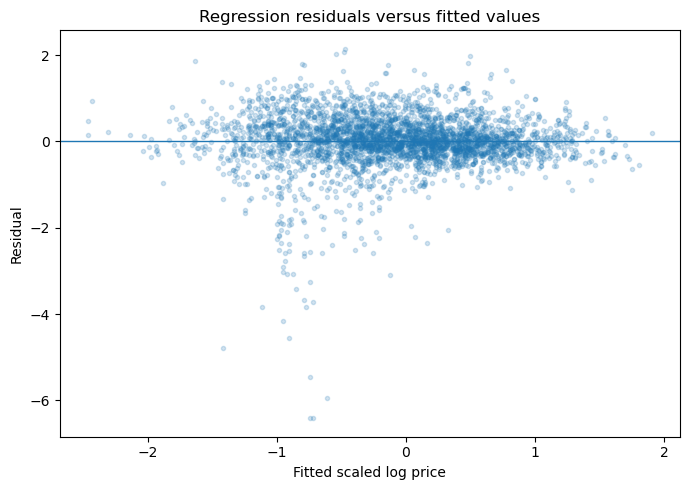

In [25]:
plt.figure(figsize=(7, 5))
plt.scatter(diagnostic_prediction, regression_residuals, s=9, alpha=0.20)
plt.axhline(0, linewidth=1)
plt.xlabel("Fitted scaled log price")
plt.ylabel("Residual")
plt.title("Regression residuals versus fitted values")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "10_regression_residuals_fitted.png", dpi=300, bbox_inches="tight")
plt.show()

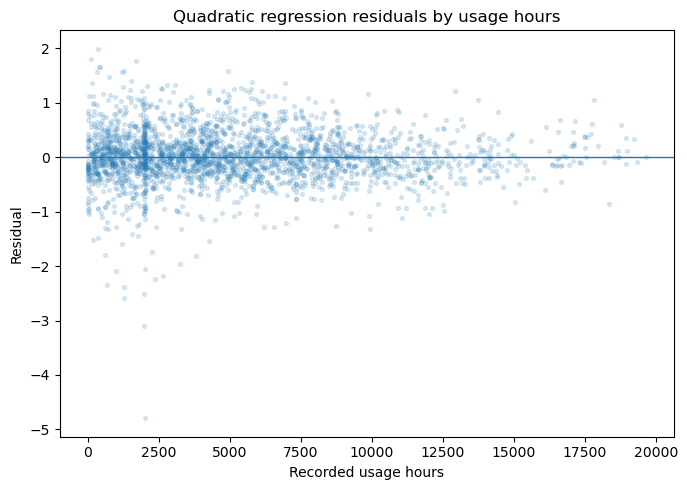

In [26]:
hours_available = validation["hours"].notna()
hours_values = validation.loc[hours_available, "hours"].to_numpy()
hours_residuals = regression_residuals[hours_available.to_numpy()]

plt.figure(figsize=(7, 5))
plt.scatter(hours_values, hours_residuals, s=8, alpha=0.15)
plt.axhline(0, linewidth=1)
plt.xlabel("Recorded usage hours")
plt.ylabel("Residual")
plt.title("Quadratic regression residuals by usage hours")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "11_regression_residuals_hours.png", dpi=300, bbox_inches="tight")
plt.show()


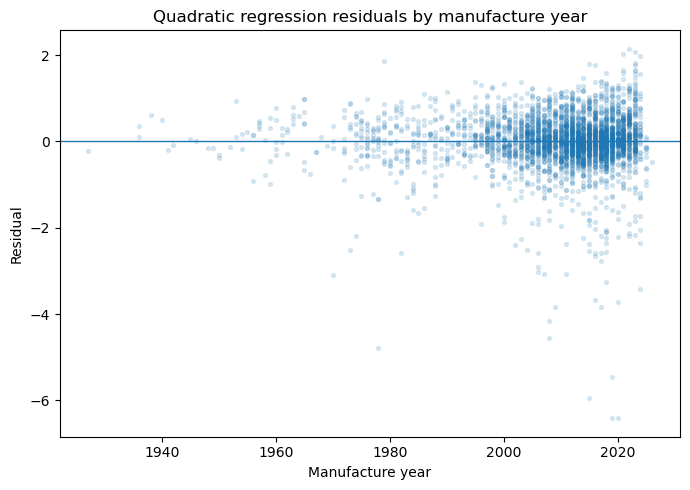

In [27]:
year_values = validation["year"].to_numpy()

plt.figure(figsize=(7, 5))
plt.scatter(year_values, regression_residuals, s=8, alpha=0.15)
plt.axhline(0, linewidth=1)
plt.xlabel("Manufacture year")
plt.ylabel("Residual")
plt.title("Quadratic regression residuals by manufacture year")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "12_regression_residuals_year.png", dpi=300, bbox_inches="tight")
plt.show()


# Tree-based models

Tree models provide a more flexible way to represent nonlinear price structure.

A **regression tree** recursively divides the predictor space using split rules such as `year < threshold`. Each terminal node predicts a constant value, so one tree can automatically represent thresholds and interactions but can be unstable if grown too deeply. This is the CART framework associated with Breiman, Friedman, Olshen and Stone (1984).

**Gradient boosting** builds many trees sequentially. Each new tree is chosen to improve the current ensemble with respect to the loss, allowing a collection of relatively small trees to approximate complex nonlinear functions; Friedman (2001) provides the foundational gradient-boosting formulation.

**XGBoost** is a regularised and computationally efficient gradient-tree-boosting system (Chen and Guestrin, 2016). In this notebook it operates on one-hot-encoded predictors.

**CatBoost** is also a gradient-boosted tree method but is designed to process categorical variables directly using ordered target statistics and ordered boosting, reducing the need for a very large one-hot representation of variables such as `model_series` (Prokhorenkova et al., 2018).

These models are tested because the EDA and regression residuals indicate curvature, thresholds and interactions that are difficult to specify exhaustively in one global regression equation.

## 14. Prepare data for CatBoost

CatBoost can use categorical variables directly, so one-hot encoding is not required. Missing numerical values are replaced by training medians, categorical values are stored as strings, and Boolean indicators are stored as 0/1.

In [28]:
def prepare_catboost(frame, numeric_medians=None):
    prepared = frame[FEATURES].copy()

    if numeric_medians is None:
        numeric_medians = prepared[NUMERIC_FEATURES].median()

    for column in NUMERIC_FEATURES:
        prepared[column] = prepared[column].fillna(numeric_medians[column]).astype(float)

    for column in CATEGORICAL_FEATURES:
        prepared[column] = prepared[column].astype("string").fillna("MISSING").astype(str)

    for column in BOOLEAN_FEATURES:
        prepared[column] = prepared[column].fillna(False).astype(int)

    return prepared, numeric_medians

In [29]:
X_train_cat, catboost_medians = prepare_catboost(train)
X_validation_cat, _ = prepare_catboost(validation, catboost_medians)
X_test_cat, _ = prepare_catboost(test, catboost_medians)

## 15. CatBoost base settings

CatBoost is evaluated in the tuning section below. Its first tuning candidate is the baseline CatBoost specification, so an additional duplicate fit is avoided.

In [30]:
catboost_default_params = {
    "loss_function": "MAE",
    "verbose": False,
    "allow_writing_files": False,
    "random_seed": RANDOM_STATE,
    "thread_count": 1,
}


# Tree-model hyperparameter tuning

The validation set is used for model tuning. The test set remains untouched.

The search is deliberately small and transparent. A small set of sensible configurations is evaluated for each tree model rather than running a very large automated search that would be harder to audit and more likely to overfit the validation set.

## 16. Decision Tree tuning candidates

In [31]:
TREE_CANDIDATES = [
    {"max_depth": 8, "min_samples_leaf": 5, "min_samples_split": 10},
    {"max_depth": 12, "min_samples_leaf": 5, "min_samples_split": 10},
    {"max_depth": 16, "min_samples_leaf": 3, "min_samples_split": 8},
    {"max_depth": 20, "min_samples_leaf": 3, "min_samples_split": 8},
    {"max_depth": None, "min_samples_leaf": 5, "min_samples_split": 10},
]

## 17. XGBoost tuning candidates

In [32]:
xgboost_base_params = {
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "reg_lambda": 1.0,
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "tree_method": "hist",
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
    "verbosity": 0,
}

XGB_CANDIDATES = [
    {"n_estimators": 450, "learning_rate": 0.05, "max_depth": 5, "min_child_weight": 1},
    {"n_estimators": 650, "learning_rate": 0.03, "max_depth": 6, "min_child_weight": 1},
    {"n_estimators": 700, "learning_rate": 0.03, "max_depth": 5, "min_child_weight": 3},
    {"n_estimators": 450, "learning_rate": 0.08, "max_depth": 4, "min_child_weight": 1},
]

## 18. CatBoost tuning candidates

In [33]:
CAT_CANDIDATES = [
    {"iterations": 500, "learning_rate": 0.05, "depth": 6, "l2_leaf_reg": 3.0},
    {"iterations": 700, "learning_rate": 0.03, "depth": 7, "l2_leaf_reg": 5.0},
]

## 19. Preprocessing for Decision Tree and XGBoost

In [34]:
tree_numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

tree_categorical = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

tree_preprocessor = ColumnTransformer([
    ("numeric", tree_numeric, NUMERIC_FEATURES),
    ("categorical", tree_categorical, CATEGORICAL_FEATURES),
    ("boolean", "passthrough", BOOLEAN_FEATURES),
])

In [35]:
# Fit the encoder once on the training data.
X_train_tree = tree_preprocessor.fit_transform(X_train)
X_validation_tree = tree_preprocessor.transform(X_validation)

print("Encoded training matrix:", X_train_tree.shape)

Encoded training matrix: (15999, 695)


## 20. Tune XGBoost

In [36]:
xgb_tuning_rows = []
xgb_models = []

for candidate_number, candidate in enumerate(XGB_CANDIDATES, start=1):
    params = xgboost_base_params.copy()
    params.update(candidate)

    print("XGBoost candidate", candidate_number, "starting", flush=True)
    model = XGBRegressor(**params)
    start_time = time.time()
    model.fit(X_train_tree, y_train)
    prediction = model.predict(X_validation_tree)
    elapsed = time.time() - start_time
    print("XGBoost candidate", candidate_number, "finished in", round(elapsed, 2), "seconds", flush=True)

    metrics = evaluate_model(validation, y_validation, prediction, target_statistics)

    xgb_models.append(model)

    xgb_tuning_rows.append({
        "model": "XGBoost",
        "candidate": candidate_number,
        "parameters": json.dumps(candidate),
        "scaled_MAE": metrics["scaled_MAE"],
        "scaled_R2": metrics["scaled_R2"],
        "MedAPE_pct": metrics["MedAPE_pct"],
        "fit_seconds": elapsed,
    })


xgb_tuning = pd.DataFrame(xgb_tuning_rows).sort_values("scaled_MAE")
xgb_tuning

XGBoost candidate 1 starting
XGBoost candidate 1 finished in 1.53 seconds
XGBoost candidate 2 starting
XGBoost candidate 2 finished in 2.41 seconds
XGBoost candidate 3 starting
XGBoost candidate 3 finished in 2.25 seconds
XGBoost candidate 4 starting
XGBoost candidate 4 finished in 1.37 seconds


,model,candidate,parameters,scaled_MAE,scaled_R2,MedAPE_pct,fit_seconds
1,XGBoost,2,"{""n_estimators"": 650, ""learning_rate"": 0.03, ""...",0.3700,0.6208,35.0326,2.4075
0,XGBoost,1,"{""n_estimators"": 450, ""learning_rate"": 0.05, ""...",0.3799,0.6041,36.6151,1.5268
2,XGBoost,3,"{""n_estimators"": 700, ""learning_rate"": 0.03, ""...",0.3802,0.6040,36.5776,2.2488
3,XGBoost,4,"{""n_estimators"": 450, ""learning_rate"": 0.08, ""...",0.3815,0.5979,36.2275,1.3714


## 21. Tune Decision Tree

In [37]:
tree_tuning_rows = []
tree_models = []

for candidate_number, candidate in enumerate(TREE_CANDIDATES, start=1):
    params = candidate.copy()
    params.update({"random_state": RANDOM_STATE})

    model = DecisionTreeRegressor(**params)
    start_time = time.time()
    model.fit(X_train_tree, y_train)
    prediction = model.predict(X_validation_tree)
    elapsed = time.time() - start_time

    metrics = evaluate_model(validation, y_validation, prediction, target_statistics)

    tree_models.append(model)

    tree_tuning_rows.append({
        "model": "Decision Tree",
        "candidate": candidate_number,
        "parameters": json.dumps(candidate),
        "scaled_MAE": metrics["scaled_MAE"],
        "scaled_R2": metrics["scaled_R2"],
        "MedAPE_pct": metrics["MedAPE_pct"],
        "fit_seconds": elapsed,
    })


tree_tuning = pd.DataFrame(tree_tuning_rows).sort_values("scaled_MAE")
tree_tuning

,model,candidate,parameters,scaled_MAE,scaled_R2,MedAPE_pct,fit_seconds
2,Decision Tree,3,"{""max_depth"": 16, ""min_samples_leaf"": 3, ""min_...",0.3943,0.5715,35.7152,0.3547
3,Decision Tree,4,"{""max_depth"": 20, ""min_samples_leaf"": 3, ""min_...",0.3982,0.5601,35.3073,0.4172
1,Decision Tree,2,"{""max_depth"": 12, ""min_samples_leaf"": 5, ""min_...",0.3990,0.5734,37.2985,0.2751
4,Decision Tree,5,"{""max_depth"": null, ""min_samples_leaf"": 5, ""mi...",0.4018,0.5559,35.4139,0.4595
0,Decision Tree,1,"{""max_depth"": 8, ""min_samples_leaf"": 5, ""min_s...",0.4326,0.5332,42.3785,0.1602


## 22. Tune CatBoost

In [38]:
cat_tuning_rows = []
cat_models = []

for candidate_number, candidate in enumerate(CAT_CANDIDATES, start=1):
    params = catboost_default_params.copy()
    params.update(candidate)

    print("CatBoost candidate", candidate_number, "starting", flush=True)

    model = CatBoostRegressor(
        cat_features=CATEGORICAL_FEATURES,
        **params,
    )

    start_time = time.time()
    model.fit(X_train_cat, y_train)
    prediction = model.predict(X_validation_cat)
    elapsed = time.time() - start_time
    print("CatBoost candidate", candidate_number, "finished in", round(elapsed, 2), "seconds", flush=True)

    metrics = evaluate_model(validation, y_validation, prediction, target_statistics)

    cat_models.append(model)

    cat_tuning_rows.append({
        "model": "CatBoost",
        "candidate": candidate_number,
        "parameters": json.dumps(candidate),
        "scaled_MAE": metrics["scaled_MAE"],
        "scaled_R2": metrics["scaled_R2"],
        "MedAPE_pct": metrics["MedAPE_pct"],
        "fit_seconds": elapsed,
    })


cat_tuning = pd.DataFrame(cat_tuning_rows).sort_values("scaled_MAE")
cat_tuning

CatBoost candidate 1 starting
CatBoost candidate 1 finished in 26.79 seconds
CatBoost candidate 2 starting
CatBoost candidate 2 finished in 44.6 seconds


,model,candidate,parameters,scaled_MAE,scaled_R2,MedAPE_pct,fit_seconds
1,CatBoost,2,"{""iterations"": 700, ""learning_rate"": 0.03, ""de...",0.3523,0.6022,30.5434,44.5970
0,CatBoost,1,"{""iterations"": 500, ""learning_rate"": 0.05, ""de...",0.3571,0.5939,30.9766,26.7921


## 23. Save all tuning results

In [39]:
tuning_results = pd.concat(
    [tree_tuning, xgb_tuning, cat_tuning],
    ignore_index=True,
).sort_values("scaled_MAE")

tuning_results.to_csv(TABLE_DIR / "17_hyperparameter_tuning_results.csv", index=False)
tuning_results.head(15)

,model,candidate,parameters,scaled_MAE,scaled_R2,MedAPE_pct,fit_seconds
9,CatBoost,2,"{""iterations"": 700, ""learning_rate"": 0.03, ""de...",0.3523,0.6022,30.5434,44.5970
10,CatBoost,1,"{""iterations"": 500, ""learning_rate"": 0.05, ""de...",0.3571,0.5939,30.9766,26.7921
5,XGBoost,2,"{""n_estimators"": 650, ""learning_rate"": 0.03, ""...",0.3700,0.6208,35.0326,2.4075
6,XGBoost,1,"{""n_estimators"": 450, ""learning_rate"": 0.05, ""...",0.3799,0.6041,36.6151,1.5268
7,XGBoost,3,"{""n_estimators"": 700, ""learning_rate"": 0.03, ""...",0.3802,0.6040,36.5776,2.2488
8,XGBoost,4,"{""n_estimators"": 450, ""learning_rate"": 0.08, ""...",0.3815,0.5979,36.2275,1.3714
0,Decision Tree,3,"{""max_depth"": 16, ""min_samples_leaf"": 3, ""min_...",0.3943,0.5715,35.7152,0.3547
1,Decision Tree,4,"{""max_depth"": 20, ""min_samples_leaf"": 3, ""min_...",0.3982,0.5601,35.3073,0.4172
2,Decision Tree,2,"{""max_depth"": 12, ""min_samples_leaf"": 5, ""min_...",0.3990,0.5734,37.2985,0.2751
3,Decision Tree,5,"{""max_depth"": null, ""min_samples_leaf"": 5, ""mi...",0.4018,0.5559,35.4139,0.4595


## 24. Select one final model

For each tree family, the candidate with the lowest validation scaled MAE is retained. These tuned tree models are then compared with the two regression models. The model with the lowest validation scaled MAE is selected before the test set is evaluated.

In [40]:
best_tree = tree_tuning.iloc[0]
best_xgb = xgb_tuning.iloc[0]
best_cat = cat_tuning.iloc[0]

best_tree_params = json.loads(best_tree["parameters"])
best_xgb_params = json.loads(best_xgb["parameters"])
best_cat_params = json.loads(best_cat["parameters"])

In [41]:
selection_table = pd.DataFrame([
    {
        "model": "Additive linear regression",
        "validation_scaled_MAE": linear_validation_metrics["scaled_MAE"],
        "parameters": "Additive linear specification",
    },
    {
        "model": "Quadratic linear regression",
        "validation_scaled_MAE": quadratic_validation_metrics["scaled_MAE"],
        "parameters": "Degree-two numeric terms",
    },
    {
        "model": "Decision Tree",
        "validation_scaled_MAE": best_tree["scaled_MAE"],
        "parameters": json.dumps(best_tree_params),
    },
    {
        "model": "XGBoost",
        "validation_scaled_MAE": best_xgb["scaled_MAE"],
        "parameters": json.dumps(best_xgb_params),
    },
    {
        "model": "CatBoost",
        "validation_scaled_MAE": best_cat["scaled_MAE"],
        "parameters": json.dumps(best_cat_params),
    },
]).sort_values("validation_scaled_MAE")

selection_table.to_csv(TABLE_DIR / "18_model_selection.csv", index=False)
selection_table

,model,validation_scaled_MAE,parameters
4,CatBoost,0.3523,"{""iterations"": 700, ""learning_rate"": 0.03, ""de..."
3,XGBoost,0.3700,"{""n_estimators"": 650, ""learning_rate"": 0.03, ""..."
2,Decision Tree,0.3943,"{""max_depth"": 16, ""min_samples_leaf"": 3, ""min_..."
1,Quadratic linear regression,0.4079,Degree-two numeric terms
0,Additive linear regression,0.4117,Additive linear specification


In [42]:
selected_model_name = selection_table.iloc[0]["model"]
selected_parameters = selection_table.iloc[0]["parameters"]

print("Selected model:", selected_model_name)
print("Selected parameters:", selected_parameters)

Selected model: CatBoost
Selected parameters: {"iterations": 700, "learning_rate": 0.03, "depth": 7, "l2_leaf_reg": 5.0}


## 25. Back-transformed validation metrics

The model-selection rule remains the pre-specified scaled MAE, but the same validation predictions are also summarised using back-transformed **MedAPE** and the shares within 20% and 30% of realised price. These percentage measures can be compared across currencies without converting currencies.

Native-price MAE and WAPE are calculated separately by currency and are retained for diagnostic reporting. CatBoost is selected before the test set is examined.


In [43]:
best_tree_model = tree_models[int(best_tree["candidate"]) - 1]
best_xgb_model = xgb_models[int(best_xgb["candidate"]) - 1]
best_cat_model = cat_models[int(best_cat["candidate"]) - 1]

validation_prediction_map = {
    "Currency median reference": np.zeros(len(validation)),
    "Additive linear regression": linear_validation_prediction,
    "Quadratic linear regression": quadratic_validation_prediction,
    "Decision Tree": best_tree_model.predict(X_validation_tree),
    "XGBoost": best_xgb_model.predict(X_validation_tree),
    "CatBoost": best_cat_model.predict(X_validation_cat),
}

validation_price_summary_rows = []
validation_currency_rows = []

for model_name, prediction in validation_prediction_map.items():
    metrics = evaluate_model(validation, y_validation, prediction, target_statistics)

    validation_price_summary_rows.append({
        "model": model_name,
        "MedAPE_pct": metrics["MedAPE_pct"],
        "within_20pct": metrics["within_20pct"],
        "within_30pct": metrics["within_30pct"],
    })

    validation_currency_rows.append(
        native_price_metrics_by_currency(
            validation,
            prediction,
            target_statistics,
            model_name,
        )
    )

validation_price_summary = (
    pd.DataFrame(validation_price_summary_rows)
    .sort_values("MedAPE_pct")
    .reset_index(drop=True)
)

validation_currency_metrics = pd.concat(validation_currency_rows, ignore_index=True)

validation_price_summary.to_csv(
    TABLE_DIR / "18a_validation_backtransformed_metrics.csv",
    index=False,
)
validation_currency_metrics.to_csv(
    TABLE_DIR / "18b_validation_native_price_metrics_by_currency.csv",
    index=False,
)

display(validation_price_summary)

validation_mae_pivot = validation_currency_metrics.pivot(
    index="model",
    columns="currency",
    values="MAE",
)
validation_mae_pivot


,model,MedAPE_pct,within_20pct,within_30pct
0,CatBoost,30.5434,36.4538,49.4605
1,XGBoost,35.0326,30.7087,44.4444
2,Decision Tree,35.7152,31.4086,43.6862
3,Quadratic linear regression,38.0101,28.6964,41.3823
4,Additive linear regression,38.0799,28.5506,41.2073
5,Currency median reference,62.0690,14.5815,23.4762


currency,AUD,CAD,EUR,GBP,USD
model,,,,,
Additive linear regression,"36,260.3988","38,900.0404","11,154.9344","9,060.2109","15,534.4144"
CatBoost,"25,389.4944","29,900.7010","7,555.7158","7,533.0717","13,341.1518"
Currency median reference,"50,231.3636","56,601.6115","20,814.0827","11,614.4469","24,594.1613"
Decision Tree,"22,665.4076","30,636.6990","9,569.7798","8,637.7180","15,209.0966"
Quadratic linear regression,"35,720.0442","38,030.8532","10,877.8644","9,137.0211","15,174.0437"
XGBoost,"25,152.2383","32,908.7983","8,259.5511","7,886.3033","13,983.3355"


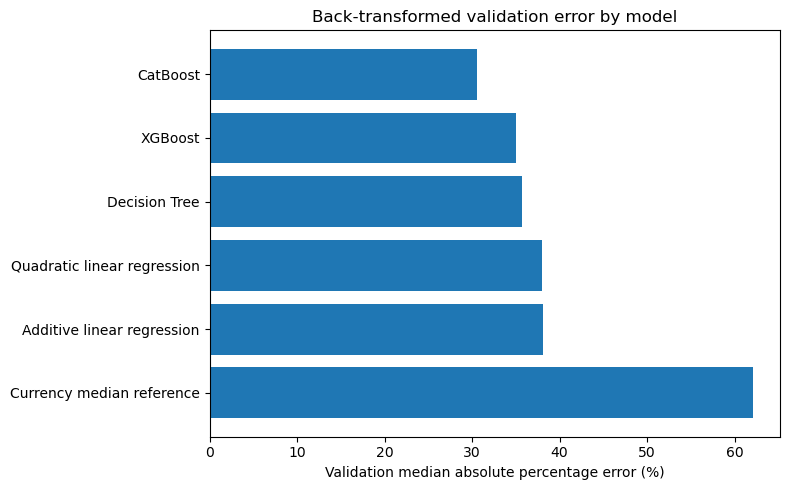

In [44]:
plt.figure(figsize=(8, 5))
plot_validation = validation_price_summary.sort_values("MedAPE_pct", ascending=False)
plt.barh(plot_validation["model"], plot_validation["MedAPE_pct"])
plt.xlabel("Validation median absolute percentage error (%)")
plt.title("Back-transformed validation error by model")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "13_validation_model_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Final test evaluation

Model and hyperparameter selection is now complete, and the test set has not been used during that process.

For the final fit, the selected CatBoost specification is re-estimated using the **combined training and validation data**. The quadratic regression is refitted on the same combined sample and serves as the substantive benchmark. The target transformation and rare-level definitions remain those learned from the original training sample, so the feature/target definitions used during model selection are unchanged.


## 26. Refit CatBoost and the quadratic benchmark on training + validation data


In [45]:
# Combine the already-preprocessed training and validation frames. Rare-level
# definitions and the target scale remain fixed from the original training data.
train_validation = pd.concat([train, validation], ignore_index=True)
y_train_validation = np.concatenate([y_train, y_validation])

# ---- Refit the selected CatBoost model ----
combined_cat_medians = train_validation[NUMERIC_FEATURES].median()
X_train_validation_cat, _ = prepare_catboost(train_validation, combined_cat_medians)
X_test_cat_final, _ = prepare_catboost(test, combined_cat_medians)

final_cat_params = catboost_default_params.copy()
final_cat_params.update(best_cat_params)

final_model = CatBoostRegressor(
    cat_features=CATEGORICAL_FEATURES,
    **final_cat_params,
)
final_model.fit(X_train_validation_cat, y_train_validation)
final_test_prediction = final_model.predict(X_test_cat_final)

# ---- Refit the quadratic regression benchmark on exactly the same rows ----
# Clone the training-stage pipeline so the final benchmark is fitted from a fresh
# estimator rather than reusing fitted preprocessing state from validation.
from sklearn.base import clone

final_quadratic_model = clone(quadratic_model)
final_quadratic_model.fit(train_validation[FEATURES], y_train_validation)
quadratic_test_prediction = final_quadratic_model.predict(test[FEATURES])

print("Final model refitted on rows:", len(train_validation))
print("Final benchmark: Quadratic linear regression")


Final model refitted on rows: 19428
Final benchmark: Quadratic linear regression


## 27. Final test metrics against the quadratic regression benchmark

The main test comparison uses **MedAPE**, because it is interpretable as a typical percentage error and remains comparable across currencies. Native-currency MAE is reported later to show the monetary size of an error within each market, but it is not used to rank currencies.

Uncertainty in the final CatBoost-versus-quadratic comparison is quantified with a **paired bootstrap**. The same test tractors are resampled with replacement for both models in each bootstrap replicate, preserving the paired nature of the comparison.


In [46]:
final_test_metrics = evaluate_model(
    test,
    y_test,
    final_test_prediction,
    target_statistics,
)

quadratic_test_metrics = evaluate_model(
    test,
    y_test,
    quadratic_test_prediction,
    target_statistics,
)

medape_reduction_vs_quadratic_pct = 100 * (
    1 - final_test_metrics["MedAPE_pct"] / quadratic_test_metrics["MedAPE_pct"]
)
medape_improvement_points = (
    quadratic_test_metrics["MedAPE_pct"] - final_test_metrics["MedAPE_pct"]
)

final_test_table = pd.DataFrame([
    {
        "model": "CatBoost",
        **final_test_metrics,
        "benchmark_model": "Quadratic linear regression",
        "benchmark_MedAPE_pct": quadratic_test_metrics["MedAPE_pct"],
        "MedAPE_improvement_points": medape_improvement_points,
        "MedAPE_relative_reduction_vs_quadratic_pct": medape_reduction_vs_quadratic_pct,
    }
])

final_test_table.to_csv(TABLE_DIR / "19_final_test_metrics.csv", index=False)
final_test_table


,model,scaled_MAE,scaled_RMSE,scaled_R2,MedAPE_pct,within_20pct,within_30pct,benchmark_model,benchmark_MedAPE_pct,MedAPE_improvement_points,MedAPE_relative_reduction_vs_quadratic_pct
0,CatBoost,0.3553,0.5729,0.6205,31.9578,34.2082,47.5941,Quadratic linear regression,40.1751,8.2172,20.4535


## 28. Save final predictions

In [47]:
actual_price = test["price"].to_numpy(dtype=float)
predicted_price = price_predictions(test, final_test_prediction, target_statistics)
quadratic_predicted_price = price_predictions(test, quadratic_test_prediction, target_statistics)

final_predictions = test[[
    "make", "model_series", "year", "hours", "currency", "drive", "price"
]].copy()

final_predictions["actual_scaled_target"] = y_test
final_predictions["predicted_scaled_target"] = final_test_prediction
final_predictions["predicted_price"] = predicted_price
final_predictions["quadratic_benchmark_predicted_price"] = quadratic_predicted_price
final_predictions["absolute_error"] = np.abs(predicted_price - actual_price)
final_predictions["absolute_percentage_error"] = final_predictions["absolute_error"] / actual_price
final_predictions["quadratic_absolute_percentage_error"] = (
    np.abs(quadratic_predicted_price - actual_price) / actual_price
)

final_predictions.to_csv(TABLE_DIR / "20_final_test_predictions.csv", index=False)
final_predictions.head()


,make,model_series,year,hours,currency,drive,price,actual_scaled_target,predicted_scaled_target,predicted_price,quadratic_benchmark_predicted_price,absolute_error,absolute_percentage_error,quadratic_absolute_percentage_error
0,John Deere,5045 E 2WD Utility,2019,978.0000,USD,4WD,"14,000.0000",-0.4372,-0.5654,"12,028.4592","13,046.6413","1,971.5408",0.1408,0.0681
1,John Deere,OTHER,2002,"2,353.0000",CAD,4WD,"66,000.0000",0.3042,0.1222,"48,910.8799","29,537.6155","17,089.1201",0.2589,0.5525
2,Case IH,Magnum 380,2024,492.0000,USD,4WD,"257,500.0000",2.0210,1.7088,"177,882.9456","156,647.4282","79,617.0544",0.3092,0.3917
3,John Deere,35G,2015,685.0000,USD,4WD,"15,000.0000",-0.3790,-0.2546,"17,381.0262","17,684.3644","2,381.0262",0.1587,0.1790
4,John Deere,OTHER,2003,NaN,USD,4WD,"19,000.0000",-0.1794,-0.9324,"7,787.8284","7,055.3912","11,212.1716",0.5901,0.6287


### Paired bootstrap confidence interval for the final MedAPE comparison

A paired bootstrap is used because both models make predictions for the same test observations. In each of 10,000 replicates, test rows are sampled with replacement and the same sampled indices are applied to both models. The 2.5th and 97.5th percentiles of the bootstrap distribution form the 95% confidence interval.


In [48]:
BOOTSTRAP_REPLICATES = 10_000
BOOTSTRAP_RANDOM_STATE = 42

catboost_ape_pct = (
    final_predictions["absolute_percentage_error"].to_numpy(dtype=float) * 100
)
quadratic_ape_pct = (
    final_predictions["quadratic_absolute_percentage_error"].to_numpy(dtype=float) * 100
)

rng = np.random.default_rng(BOOTSTRAP_RANDOM_STATE)
n_test = len(final_predictions)

catboost_bootstrap_medape = np.empty(BOOTSTRAP_REPLICATES)
quadratic_bootstrap_medape = np.empty(BOOTSTRAP_REPLICATES)
medape_improvement_bootstrap = np.empty(BOOTSTRAP_REPLICATES)
relative_reduction_bootstrap = np.empty(BOOTSTRAP_REPLICATES)

for b in range(BOOTSTRAP_REPLICATES):
    sampled_indices = rng.integers(0, n_test, size=n_test)

    catboost_medape_b = np.median(catboost_ape_pct[sampled_indices])
    quadratic_medape_b = np.median(quadratic_ape_pct[sampled_indices])

    catboost_bootstrap_medape[b] = catboost_medape_b
    quadratic_bootstrap_medape[b] = quadratic_medape_b
    medape_improvement_bootstrap[b] = quadratic_medape_b - catboost_medape_b
    relative_reduction_bootstrap[b] = 100 * (
        quadratic_medape_b - catboost_medape_b
    ) / quadratic_medape_b


def percentile_interval(values, lower=2.5, upper=97.5):
    return np.percentile(values, [lower, upper])


catboost_ci = percentile_interval(catboost_bootstrap_medape)
quadratic_ci = percentile_interval(quadratic_bootstrap_medape)
improvement_ci = percentile_interval(medape_improvement_bootstrap)
relative_reduction_ci = percentile_interval(relative_reduction_bootstrap)

bootstrap_summary = pd.DataFrame([
    {
        "metric": "CatBoost MedAPE (%)",
        "estimate": final_test_metrics["MedAPE_pct"],
        "CI_2.5pct": catboost_ci[0],
        "CI_97.5pct": catboost_ci[1],
    },
    {
        "metric": "Quadratic regression MedAPE (%)",
        "estimate": quadratic_test_metrics["MedAPE_pct"],
        "CI_2.5pct": quadratic_ci[0],
        "CI_97.5pct": quadratic_ci[1],
    },
    {
        "metric": "MedAPE improvement (percentage points)",
        "estimate": medape_improvement_points,
        "CI_2.5pct": improvement_ci[0],
        "CI_97.5pct": improvement_ci[1],
    },
    {
        "metric": "Relative reduction in MedAPE (%)",
        "estimate": medape_reduction_vs_quadratic_pct,
        "CI_2.5pct": relative_reduction_ci[0],
        "CI_97.5pct": relative_reduction_ci[1],
    },
])

bootstrap_summary.to_csv(
    TABLE_DIR / "20b_test_medape_bootstrap_ci.csv",
    index=False,
)

bootstrap_summary


,metric,estimate,CI_2.5pct,CI_97.5pct
0,CatBoost MedAPE (%),31.9578,30.5645,33.3772
1,Quadratic regression MedAPE (%),40.1751,38.7616,42.2009
2,MedAPE improvement (percentage points),8.2172,6.5990,10.0613
3,Relative reduction in MedAPE (%),20.4535,16.7022,24.2505


## 29. Actual versus predicted values

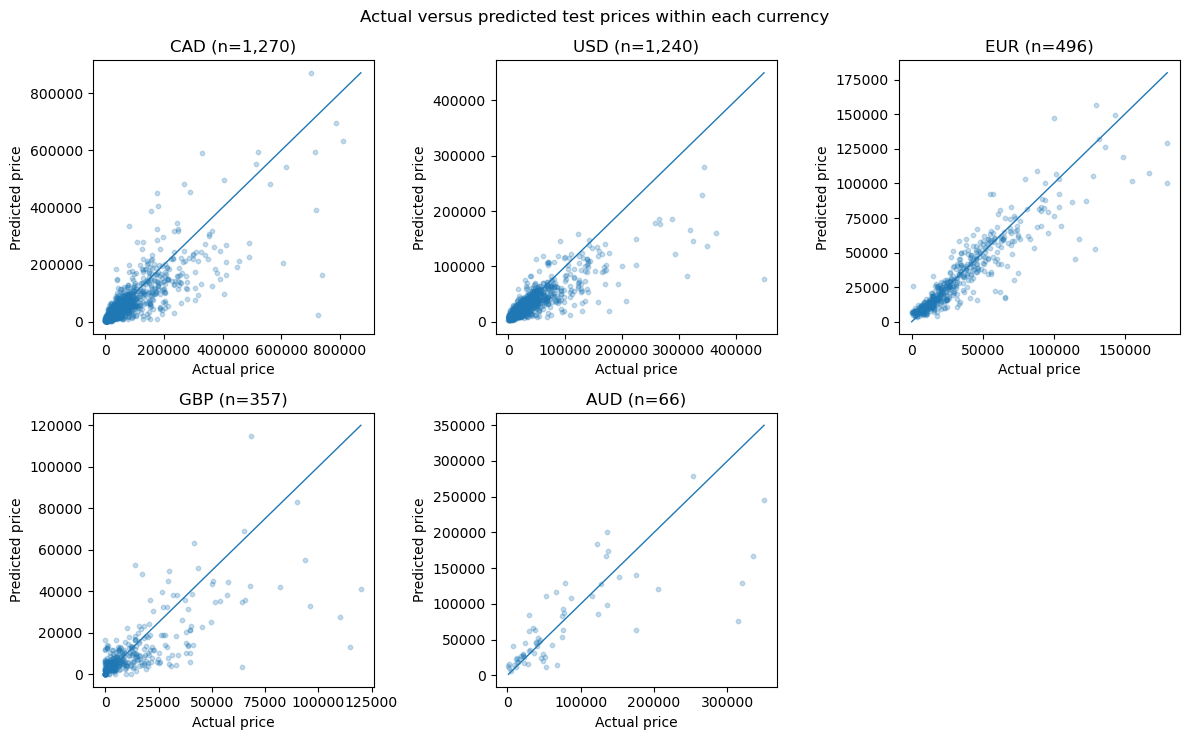

In [49]:
currencies_for_plot = (
    final_predictions["currency"]
    .value_counts()
    .index
    .tolist()
)

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
axes = axes.ravel()

for axis, currency in zip(axes, currencies_for_plot):
    group = final_predictions.loc[
        final_predictions["currency"].eq(currency)
    ]

    actual = group["price"].to_numpy(dtype=float)
    predicted = group["predicted_price"].to_numpy(dtype=float)

    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    axis.scatter(actual, predicted, s=10, alpha=0.25)
    axis.plot([lower, upper], [lower, upper], linewidth=1)
    axis.set_title(f"{currency} (n={len(group):,})")
    axis.set_xlabel("Actual price")
    axis.set_ylabel("Predicted price")
    axis.ticklabel_format(style="plain", axis="both")

for axis in axes[len(currencies_for_plot):]:
    axis.axis("off")

fig.suptitle("Actual versus predicted test prices within each currency")
fig.tight_layout()
plt.savefig(
    FIGURE_DIR / "14_test_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Error analysis

A single percentage metric can hide important differences between markets. The final model is therefore evaluated separately for each currency in its **actual price units**, and then by model-series support using cross-currency percentage errors.

## 30. Performance by currency

In [50]:
def summarise_prediction_groups(frame, group_column):
    """Cross-currency subgroup summary using unit-free percentage metrics."""
    rows = []

    for group_name, group in frame.groupby(group_column, observed=True):
        actual = group["price"].to_numpy(dtype=float)
        predicted = group["predicted_price"].to_numpy(dtype=float)
        percentage_error = np.abs(predicted - actual) / actual

        rows.append({
            group_column: group_name,
            "n": len(group),
            "MedAPE_pct": 100 * np.median(percentage_error),
            "within_20pct": 100 * np.mean(percentage_error <= 0.20),
            "within_30pct": 100 * np.mean(percentage_error <= 0.30),
        })

    return pd.DataFrame(rows)


def final_currency_metrics_with_quadratic_benchmark(
    frame,
    final_prediction,
    benchmark_prediction,
    statistics,
):
    model_metrics = native_price_metrics_by_currency(
        frame,
        final_prediction,
        statistics,
        "CatBoost",
    )

    benchmark_metrics = native_price_metrics_by_currency(
        frame,
        benchmark_prediction,
        statistics,
        "Quadratic linear regression",
    )

    benchmark_keep = benchmark_metrics[[
        "currency",
        "MAE",
        "MedAPE_pct",
        "WAPE_pct",
        "within_30pct",
    ]].rename(columns={
        "MAE": "quadratic_MAE",
        "MedAPE_pct": "quadratic_MedAPE_pct",
        "WAPE_pct": "quadratic_WAPE_pct",
        "within_30pct": "quadratic_within_30pct",
    })

    result = model_metrics.merge(benchmark_keep, on="currency", how="left")
    result["MedAPE_improvement_points"] = (
        result["quadratic_MedAPE_pct"] - result["MedAPE_pct"]
    )
    result["MedAPE_relative_reduction_vs_quadratic_pct"] = 100 * (
        1 - result["MedAPE_pct"] / result["quadratic_MedAPE_pct"]
    )
    return result


In [51]:
currency_metrics = final_currency_metrics_with_quadratic_benchmark(
    test,
    final_test_prediction,
    quadratic_test_prediction,
    target_statistics,
)

currency_metrics = currency_metrics.sort_values("currency")
currency_metrics.to_csv(
    TABLE_DIR / "21_test_native_price_metrics_by_currency.csv",
    index=False,
)
currency_metrics


,model,currency,n,median_actual_price,MAE,RMSE,MedAE,price_R2,MedAPE_pct,WAPE_pct,within_20pct,within_30pct,quadratic_MAE,quadratic_MedAPE_pct,quadratic_WAPE_pct,quadratic_within_30pct,MedAPE_improvement_points,MedAPE_relative_reduction_vs_quadratic_pct
0,CatBoost,AUD,66,"45,000.0000","31,619.5940","54,102.8160","15,624.4160",0.5778,35.4960,40.8031,28.7879,43.9394,"30,097.6800",34.3597,38.8391,43.9394,-1.1363,-3.3072
1,CatBoost,CAD,1270,"38,000.0000","29,225.4046","57,811.6626","12,721.2516",0.6460,40.0355,40.9365,25.5118,39.2126,"39,639.0550",50.4296,55.5230,28.2677,10.3941,20.6111
2,CatBoost,EUR,496,"26,000.0000","7,593.5352","12,926.4883","4,238.1436",0.8154,18.0500,21.8605,53.6290,68.1452,"9,478.2817",24.9171,27.2864,59.0726,6.8671,27.5599
3,CatBoost,GBP,357,"6,400.0000","7,373.1311","13,656.9636","3,455.3288",0.4747,57.5175,54.7732,16.5266,24.0896,"10,069.7501",71.4696,74.8057,15.6863,13.9521,19.5217
4,CatBoost,USD,1240,"23,000.0000","12,793.0297","27,335.5920","5,865.1086",0.6309,26.0962,34.8527,40.7258,54.9194,"14,994.7504",30.3932,40.8510,49.4355,4.2970,14.1379


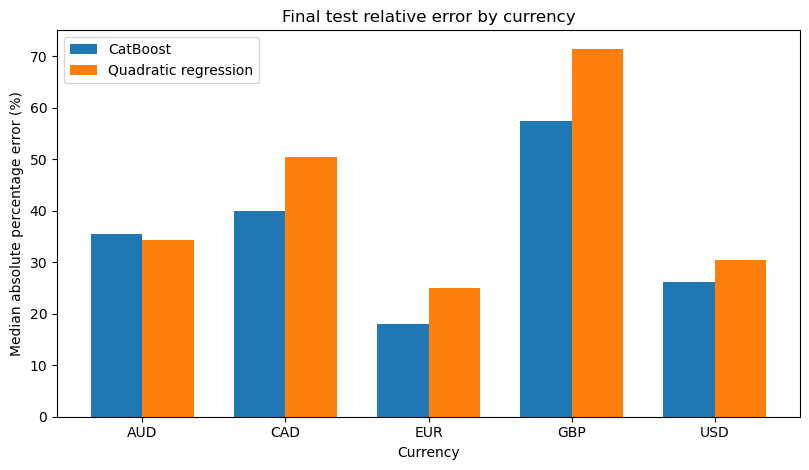

In [52]:
plot_currency = currency_metrics.sort_values("currency")
x = np.arange(len(plot_currency))
width = 0.36

plt.figure(figsize=(8.2, 4.8))
plt.bar(
    x - width / 2,
    plot_currency["MedAPE_pct"],
    width,
    label="CatBoost",
)
plt.bar(
    x + width / 2,
    plot_currency["quadratic_MedAPE_pct"],
    width,
    label="Quadratic regression",
)

plt.xticks(x, plot_currency["currency"])
plt.xlabel("Currency")
plt.ylabel("Median absolute percentage error (%)")
plt.title("Final test relative error by currency")
plt.legend()
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "15_test_error_by_currency.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 31. Performance for common versus rare/unseen model series

In [53]:
final_predictions["model_series_support"] = np.where(
    test["model_series"].eq("OTHER"),
    "Rare or unseen",
    "Common in training data",
)

series_support_metrics = summarise_prediction_groups(
    final_predictions,
    "model_series_support",
)

series_support_metrics.to_csv(
    TABLE_DIR / "22_test_metrics_by_model_series_support.csv",
    index=False,
)
series_support_metrics

,model_series_support,n,MedAPE_pct,within_20pct,within_30pct
0,Common in training data,1605,22.5544,44.3614,60.3738
1,Rare or unseen,1824,44.0237,25.2741,36.3487


# Model interpretation

Permutation importance is used to measure predictive importance. Each original feature is shuffled and the resulting increase in scaled MAE is recorded. A large increase means that the fitted model relied strongly on that feature.

These values describe prediction, not causal effects.

## 32. Define a prediction function for the final model

In [54]:
def predict_with_final_model(frame):
    X_cat, _ = prepare_catboost(frame, combined_cat_medians)
    return final_model.predict(X_cat)


## 33. Calculate permutation importance

In [55]:
importance_sample = test.sample(
    n=min(1500, len(test)),
    random_state=RANDOM_STATE,
).reset_index(drop=True)

importance_y = transform_target(importance_sample, target_statistics)
base_prediction = predict_with_final_model(importance_sample)
base_mae = mean_absolute_error(importance_y, base_prediction)

importance_rows = []
random_generator = np.random.default_rng(RANDOM_STATE)

for feature in FEATURES:
    increases = []

    for repeat in range(3):
        shuffled = importance_sample.copy()
        shuffled[feature] = random_generator.permutation(shuffled[feature].to_numpy())

        shuffled_prediction = predict_with_final_model(shuffled)
        shuffled_mae = mean_absolute_error(importance_y, shuffled_prediction)
        increases.append(shuffled_mae - base_mae)

    importance_rows.append({
        "feature": feature,
        "importance_mean": np.mean(increases),
        "importance_std": np.std(increases, ddof=1),
    })

permutation_table = (
    pd.DataFrame(importance_rows)
    .sort_values("importance_mean", ascending=False)
)

permutation_table.to_csv(TABLE_DIR / "23_permutation_importance.csv", index=False)
permutation_table.head(15)

,feature,importance_mean,importance_std
0,year,0.1230,0.0044
3,model_series,0.0970,0.0057
13,air_conditioning,0.0863,0.0087
2,make,0.0487,0.0018
5,currency,0.0419,0.0015
24,hours_missing,0.0296,0.0037
4,country,0.0286,0.0008
15,isobus,0.0265,0.0019
1,hours,0.0239,0.0001
12,cab,0.0212,0.0016


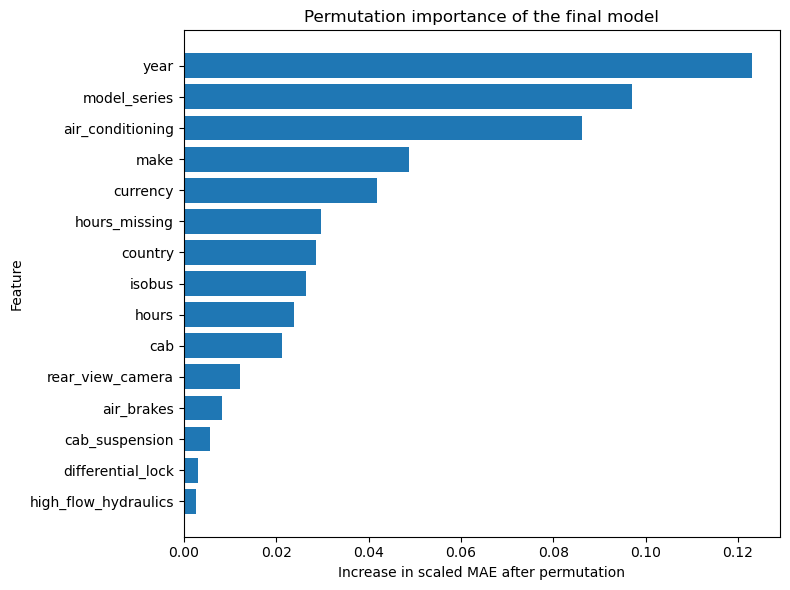

In [56]:
plot_importance = permutation_table.head(15).sort_values("importance_mean")

plt.figure(figsize=(8, 6))
plt.barh(plot_importance["feature"], plot_importance["importance_mean"])
plt.xlabel("Increase in scaled MAE after permutation")
plt.ylabel("Feature")
plt.title("Permutation importance of the final model")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "17_permutation_importance.png", dpi=300, bbox_inches="tight")
plt.show()

## 34. Save model metadata and fitted model output

The saved metadata records the selected model, tuning parameters, target-scaling statistics and software versions. The fitted model itself is also saved using the model's native format where practical.

In [57]:
metadata = {
    "selected_model": selected_model_name,
    "selected_parameters": selected_parameters,
    "final_benchmark": "Quadratic linear regression",
    "random_state": RANDOM_STATE,
    "training_rows": len(train_raw),
    "validation_rows": len(validation_raw),
    "final_refit_rows": len(train_validation),
    "test_rows": len(test_raw),
    "target_scaler_fitted_on": "original training split",
    "rare_level_definitions_fitted_on": "original training split",
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
}

with open(MODEL_DIR / "final_model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

target_statistics.to_csv(MODEL_DIR / "final_target_scaler.csv")


In [58]:
final_model.save_model(MODEL_DIR / "final_catboost_model.cbm")

import joblib
joblib.dump(final_quadratic_model, MODEL_DIR / "final_quadratic_benchmark.joblib")


['outputs\\models\\final_quadratic_benchmark.joblib']

## 35. Final output summary

In [59]:
print("Selected final model:", selected_model_name)
print()
print("Final test results:")
display(final_test_table)
print()
print("Saved figures:", len(list(FIGURE_DIR.glob("*.png"))))
print("Saved tables:", len(list(TABLE_DIR.glob("*.csv"))))
print("Saved model files:", len(list(MODEL_DIR.iterdir())))

Selected final model: CatBoost

Final test results:


,model,scaled_MAE,scaled_RMSE,scaled_R2,MedAPE_pct,within_20pct,within_30pct,benchmark_model,benchmark_MedAPE_pct,MedAPE_improvement_points,MedAPE_relative_reduction_vs_quadratic_pct
0,CatBoost,0.3553,0.5729,0.6205,31.9578,34.2082,47.5941,Quadratic linear regression,40.1751,8.2172,20.4535



Saved figures: 20
Saved tables: 30
Saved model files: 4


## References used to describe model families

These sources are used to explain and contextualise the statistical methods; the project itself was initiated from the supplied data and business question rather than as an extension of a particular tractor-pricing paper.

- Breiman, L., Friedman, J. H., Olshen, R. A. and Stone, C. J. (1984). *Classification and Regression Trees*.
- Friedman, J. H. (2001). “Greedy Function Approximation: A Gradient Boosting Machine.” *The Annals of Statistics*, 29(5), 1189–1232.
- Chen, T. and Guestrin, C. (2016). “XGBoost: A Scalable Tree Boosting System.” *Proceedings of KDD 2016*.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V. and Gulin, A. (2018). “CatBoost: unbiased boosting with categorical features.” *NeurIPS 2018*.
- Feuz, R. (2023). “Hedonic Price Analysis of Used Tractors.” This paper is treated as later contextual literature rather than the origin of the project.